<div style="border-radius:22px; padding:34px 30px 28px; background:linear-gradient(120deg, #C00000 0%, #6e0000 100%); color:#ffffff">
<div style="font-size:11px; letter-spacing:.32em; color:#ffc9c9">M.I.A ROBOTICS · VIDEO ENGINEERING SESSION</div>
<div style="font-size:34px; font-weight:800; margin:10px 0 6px">ROV Video Streaming Lab</div>
<div style="font-size:15px; color:#ffe1e1">Every experiment from the talk, in the order of the slides. Drag, encode, look.</div>
</div>

This notebook goes with `presentation/MIA_Video_Streaming.pptx`. Each red banner names the slide it belongs to, so you can open the matching experiment while the slide is on the screen.

**How to use it**

1. Run everything once: **Kernel → Restart Kernel and Run All Cells**. It takes 10–20 minutes the first time (it encodes a lot of video). After that, results are cached in `work/` and it's quick.
2. Then play with the panels. Panels marked **live** update while you drag. Panels marked **press Encode** re-encode real video with your settings.
3. Every number here is measured on *this* computer or calculated from a formula you can read in the cell. Anything that is a model or an estimate says so.

The test clip is a synthetic underwater scene (a pipeline, haze, marine snow, sensor noise). To use your own footage, set `ROV_SOURCE` before starting Jupyter: `ROV_SOURCE=my_dive.mp4 jupyter lab`.

**Contents**

| Slide | Part | Experiment | How |
|---|---|---|---|
| 6 | Physics first | What does the water cost in bits? | press Encode |
| 9 | Camera choice | Will the USB bus take another camera? | live: changes as you drag |
| 13–14 | Counting bits | How big is raw video? | live: changes as you drag |
| 15 | Counting bits | One hour of video, in Egyptian pounds | live: changes as you drag |
| 16 | Activity 1 | Check your card | live: changes as you drag |
| 17 | Measured | Same clip, four codecs | press Encode |
| 18 | Words that get mixed up | What does one packet cost on the wire? | live: changes as you drag |
| 21–22 | Digital video fundamentals | Colour at half resolution: can you see it? | live: changes as you drag |
| 23–25 | Prediction | Find the block in the last frame | live: changes as you drag |
| 26 | Transform + quantize | Where the bits are thrown away | live: changes as you drag |
| 28 | Frame types | I, P and B frames, and the GOP | press Encode |
| 29 | Experiments 3 and 6 | Quality target or bitrate cap? | press Encode |
| 30 | Why streamers obsess over bits | What is 1 % of Netflix's bitrate worth? | live: changes as you drag |
| 32 | Choosing a codec | The fair comparison: whole rate–quality curves | runs once |
| 33 | Codec ≠ container | Pull the power during a recording | press Encode |
| 34–35 | MJPEG on the ROV | The resolution trap | press Encode |
| 38 | Experiment 4 | Encoder presets: CPU against bits | press Encode |
| 39 | Experiment 5 | Packet loss and the keyframe interval | press Encode |
| 40 | Experiment 6 | PSNR, SSIM, and your own eyes | live: changes as you drag |
| 40 | Activity 3 | The blind test | press Encode |
| 42 | Who does the work? | Is the hardware encoder really there? | runs once |
| 43–45 | Jetson Nano vs Raspberry Pi 5 | How many streams can the ROV computer encode? | runs once |
| 46 | Reliability lesson from 2023 | Read the throttle flags | live: changes as you drag |
| 47 | Getting bits to the browser | TCP or UDP when packets get lost? | live: changes as you drag |
| 48 | Experiment 9 estimate | Build your own latency budget | live: changes as you drag |
| 49 | Experiment 9 measured | How many frames does the encoder hold? | runs once |
| 50 | Experiment 8 | Eight cameras on one tether | live: changes as you drag |
| 51 | Camera selection | Share a shrinking tether | live: changes as you drag |
| 52 | Streaming for computer vision | What compression does to corners | press Encode |
| 54 · 72 | Where is the problem? | Latency drift: a queue that only grows | live: changes as you drag |
| 73 | Field guide | A frozen picture that looks live | live: changes as you drag |
| 57 | Measure latency three ways | Your glass-to-glass readings | live: changes as you drag |
| 61 | The checklist | Run the health check | runs once |
| 62 | A practical optimization strategy | Design the eight-camera system | live: changes as you drag |
| 62 | Engineering log | What this run measured | runs once |

## Setup

Run these three cells and move on. They load the tools, make the test clip, and build the control panels. You don't need to read them to do the experiments, but everything below calls them, so they're short and plain.

```bash
pip install -r requirements.txt     # numpy pandas matplotlib scipy jupyterlab ipywidgets av
```
FFmpeg 5 or newer must be on your `PATH` (with `libx264`; `libx265` and `libsvtav1` are optional).

In [1]:
import os, sys, json, time, shutil, subprocess, resource, re, math, platform, random
from pathlib import Path
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FFMPEG, FFPROBE = shutil.which("ffmpeg"), shutil.which("ffprobe")
assert FFMPEG and FFPROBE, "FFmpeg/ffprobe not found on PATH — see the installation section."

WORK = Path("work"); WORK.mkdir(exist_ok=True)
CPU_CORES = os.cpu_count()

# ---- chart style: one consistent, colour-blind-checked palette -------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CRITICAL = "#c62828"   # reserved for "over the limit" — never used as a series colour
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e2de", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 2)

def run(cmd, check=True):
    """Run a command; return wall time, CPU time (user+sys of the child) and stderr."""
    r0 = resource.getrusage(resource.RUSAGE_CHILDREN); t0 = time.perf_counter()
    p = subprocess.run(cmd, capture_output=True, text=True)
    wall = time.perf_counter() - t0; r1 = resource.getrusage(resource.RUSAGE_CHILDREN)
    cpu = (r1.ru_utime - r0.ru_utime) + (r1.ru_stime - r0.ru_stime)
    if check and p.returncode != 0:
        raise RuntimeError(f"Command failed ({p.returncode}): {' '.join(map(str, cmd))}\n{p.stderr[-1500:]}")
    return {"wall_s": wall, "cpu_s": cpu, "rc": p.returncode, "stderr": p.stderr, "stdout": p.stdout}

def probe(path):
    out = run([FFPROBE, "-v", "error", "-show_streams", "-show_format", "-of", "json", str(path)])["stdout"]
    j = json.loads(out); v = next(s for s in j["streams"] if s["codec_type"] == "video")
    dur = float(j["format"].get("duration", v.get("duration", 0)) or 0)
    size = Path(path).stat().st_size
    return {"codec": v["codec_name"], "profile": v.get("profile"), "pix_fmt": v.get("pix_fmt"),
            "width": v["width"], "height": v["height"], "fps": float(Fraction(v["avg_frame_rate"])) if v["avg_frame_rate"] != "0/0" else None,
            "duration_s": dur, "size_bytes": size, "bitrate_mbps": size * 8 / dur / 1e6 if dur else None}

def packets(path):
    """Per-packet table: pts (s), size (bytes), keyframe flag."""
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "packet=pts_time,size,flags,pos",
               "-of", "csv=p=0", str(path)])["stdout"]
    rows = []
    for line in out.strip().splitlines():
        parts = line.split(",")
        if len(parts) < 4 or parts[0] in ("", "N/A"): continue
        rows.append((float(parts[0]), int(parts[1]), int(parts[2]) if parts[2] not in ("", "N/A") else -1, "K" in parts[3]))
    return pd.DataFrame(rows, columns=["pts", "size", "pos", "key"]).sort_values("pts").reset_index(drop=True)

def frame_types(path):
    out = run([FFPROBE, "-v", "error", "-select_streams", "v:0", "-show_entries", "frame=pict_type,pkt_size",
               "-of", "json", str(path)])["stdout"]
    frames = json.loads(out).get("frames", [])
    return pd.DataFrame([(f.get("pict_type", "?"), int(f.get("pkt_size", 0))) for f in frames], columns=["type", "size"])

def quality(dist, ref, width=None, height=None, per_frame=False):
    """PSNR (dB, luma+chroma average) and SSIM (0..1) of `dist` against `ref`.
    The distorted video is scaled back to the reference size first, so substreams can be compared too."""
    info = probe(ref); w, h = width or info["width"], height or info["height"]
    plog, slog = WORK / "psnr.log", WORK / "ssim.log"
    # Timestamps are snapped to the reference frame grid (settb): containers such as MKV store ms-rounded
    # timestamps, and without this every third frame would be compared with the wrong reference frame.
    sync = f"setpts=PTS-STARTPTS,settb=1/{FPS}"
    graph = (f"[0:v]scale={w}:{h}:flags=bicubic,format=yuv420p,{sync},split[d1][d2];"
             f"[1:v]format=yuv420p,{sync},split[r1][r2];"
             f"[d1][r1]psnr=stats_file={plog}[o1];[d2][r2]ssim=stats_file={slog}[o2]")
    ref_in = SRC_IN if Path(ref) == SRC else ["-i", str(ref)]
    r = run([FFMPEG, "-hide_banner", "-i", str(dist), *ref_in, "-lavfi", graph,
             "-map", "[o1]", "-f", "null", "-", "-map", "[o2]", "-f", "null", "-"])
    psnr = float(re.search(r"PSNR .*average:([\d.]+|inf)", r["stderr"]).group(1).replace("inf", "99"))
    ssim = float(re.search(r"SSIM .*All:([\d.]+)", r["stderr"]).group(1))
    if not per_frame:
        return psnr, ssim
    pf = [min(float(m.group(1).replace("inf", "99")), 99) for m in re.finditer(r"psnr_avg:([\d.]+|inf)", plog.read_text())]
    return psnr, ssim, np.array(pf)

def mbps_fmt(x, _=None):
    return f"{x:,.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2f}")

ENCODERS = run([FFMPEG, "-hide_banner", "-encoders"])["stdout"]
FILTERS = run([FFMPEG, "-hide_banner", "-filters"])["stdout"]
HAS = {name: (f" {name} " in ENCODERS) for name in ["libx264", "libx265", "libsvtav1", "libaom-av1", "mjpeg",
                                                   "h264_nvenc", "h264_vaapi", "h264_qsv", "h264_v4l2m2m"]}
HAS["libvmaf"] = " libvmaf " in FILTERS
print(run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0])
print(f"Python {platform.python_version()} on {platform.machine()} · {CPU_CORES} CPU cores")
print("Available:", ", ".join(k for k, v in HAS.items() if v))
print("Missing:  ", ", ".join(k for k, v in HAS.items() if not v) or "—")

ffmpeg version 7.1.1-1ubuntu4.2 Copyright (c) 2000-2025 the FFmpeg developers
Python 3.13.7 on x86_64 · 8 CPU cores
Available: libx264, libx265, libsvtav1, libaom-av1, mjpeg, h264_nvenc, h264_vaapi, h264_qsv, h264_v4l2m2m
Missing:   libvmaf


Synthetic clip generated in 41.9 s
{'codec': 'ffv1', 'profile': None, 'pix_fmt': 'yuv420p', 'width': 1280, 'height': 720, 'fps': 30.0, 'duration_s': 6.0, 'size_bytes': 60625299, 'bitrate_mbps': 80.833732}


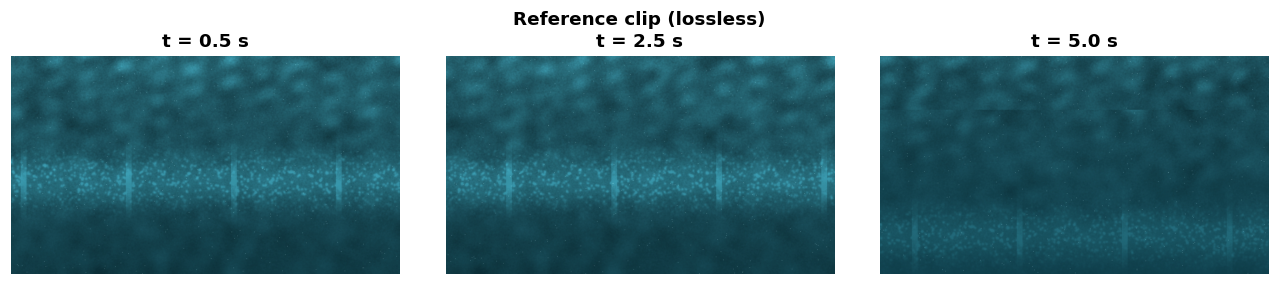

In [2]:
ROV_SOURCE = os.environ.get("ROV_SOURCE")   # e.g. "my_dive.mp4" — leave None for the synthetic clip
W, H, FPS, SECONDS = 1280, 720, 30, 6
N_FRAMES = FPS * SECONDS
SRC = WORK / "source.mkv"

def synth_underwater_clip(path, w=W, h=H, fps=FPS, n=N_FRAMES, seed=7):
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(seed)
    pan = 3                                             # pixels per frame of camera pan
    tex_w = w + 1200
    # Seabed / pipeline texture: low-frequency "rock" + high-frequency detail
    lo = gaussian_filter(rng.standard_normal((h, tex_w)), 18); lo /= np.abs(lo).max()
    hi = gaussian_filter(rng.standard_normal((h, tex_w)), 1.5); hi /= np.abs(hi).max()
    tex = 0.55 + 0.25 * lo + 0.12 * hi
    yy = np.arange(h)[:, None]
    pipe = np.exp(-((yy - 0.58 * h) / (0.11 * h)) ** 2)                # a horizontal pipeline
    seams = (np.sin(np.arange(tex_w) / 55.0) > 0.985).astype(float)    # weld seams
    tex = tex * (1 - 0.6 * pipe) + pipe * (0.75 + 0.15 * hi + 0.4 * seams[None, :])
    growth = gaussian_filter((rng.random((h, tex_w)) > 0.996).astype(float), 3) * 25
    tex = np.clip(tex + growth * pipe, 0, 1.4)
    depth = np.linspace(0, 1, h)[:, None]
    water = np.array([18, 92, 110]) / 255.0                            # blue-green water colour
    tint = np.array([0.35, 0.85, 0.95])                                # red absorbed first
    xs = np.arange(w)[None, :]
    p_n = 350; px = rng.uniform(0, w, p_n); py = rng.uniform(0, h, p_n)
    vx = rng.normal(0.4, 0.5, p_n); vy = rng.normal(-0.6, 0.4, p_n)
    cmd = [FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24",
           "-s", f"{w}x{h}", "-r", str(fps), "-i", "-", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(path)]
    proc = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    for i in range(n):
        t = i / fps
        if i < int(0.66 * n):                                          # camera 1: pan along the pipe
            view = tex[:, i * pan:i * pan + w]; turb = 0.35
        else:                                                          # camera 2: closer, darker view
            off = 600 + (i - int(0.66 * n)) * 2
            view = np.roll(tex[:, off:off + w], h // 4, axis=0) * 0.85; turb = 0.5
        caustic = (np.sin(xs / 37.0 + 2.1 * t) * np.sin(yy / 23.0 - 1.7 * t + xs / 90.0)) ** 2
        light = 0.75 + 0.35 * caustic * np.exp(-3 * depth)
        lum = view * light * (1.05 - 0.55 * depth)
        rgb = lum[..., None] * tint[None, None, :]
        haze = turb * (0.4 + 0.6 * depth)[..., None]                   # turbidity: fade to water colour
        rgb = rgb * (1 - haze) + water[None, None, :] * haze
        px += vx; py += vy; px %= w; py %= h                           # marine snow
        ix, iy = px.astype(int), py.astype(int)
        for dx, dy, a in ((0, 0, 0.5), (1, 0, 0.25), (0, 1, 0.25)):
            np.add.at(rgb, ((iy + dy) % h, (ix + dx) % w), a)
        rgb += rng.normal(0, 0.004, rgb.shape)                         # sensor noise (camera gain)
        proc.stdin.write((np.clip(rgb, 0, 1) * 255).astype(np.uint8).tobytes())
    proc.stdin.close(); proc.wait()

if not SRC.exists():
    if ROV_SOURCE:
        run([FFMPEG, "-y", "-hide_banner", "-i", ROV_SOURCE, "-t", str(SECONDS), "-vf",
             f"scale={W}:{H}:force_original_aspect_ratio=decrease,pad={W}:{H}:(ow-iw)/2:(oh-ih)/2,fps={FPS}",
             "-an", "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(SRC)])
    else:
        t0 = time.time(); tmp = WORK / "source_tmp.mkv"; synth_underwater_clip(tmp); tmp.rename(SRC)
        print(f"Synthetic clip generated in {time.time()-t0:.1f} s")

# Encoders read an uncompressed copy, so CPU measurements contain (almost) only encoding work.
SRC_RAW = WORK / "source.yuv"
if not SRC_RAW.exists():
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(SRC), "-f", "rawvideo", "-pix_fmt", "yuv420p", str(SRC_RAW)])
SRC_IN = ["-f", "rawvideo", "-pix_fmt", "yuv420p", "-s", f"{W}x{H}", "-r", str(FPS), "-i", str(SRC_RAW)]
info = probe(SRC); print(info)
# Show three frames from the clip
fig, axs = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, t in zip(axs, (0.5, 2.5, 5.0)):
    png = WORK / f"src_{t}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(SRC), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(f"t = {t} s"); ax.axis("off")
plt.suptitle("Reference clip (lossless)", fontweight="bold"); plt.tight_layout(); plt.show()

In [3]:
import hashlib
from IPython.display import HTML, Markdown, display

try:
    import ipywidgets as wdg
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

display(HTML("<style>.jp-OutputArea-output img, .output_png img {display:block; margin:0 auto}"
             " .jp-RenderedHTMLCommon table {margin-left:auto; margin-right:auto}</style>"))

MIA_RED = "#C00000"
GOOD, BAD, GREY = "#2e7d32", "#c62828", "#8a8a8a"
BATCH = os.environ.get("NB_BATCH") == "1"   # set when the notebook is run unattended (build/run_nb.py)


def rate(mbps):
    """1493 -> '1.49 Gb/s', 8.2 -> '8.2 Mb/s', 0.42 -> '0.42 Mb/s'."""
    if mbps >= 1000:
        return f"{mbps / 1000:.2f} Gb/s"
    return f"{mbps:,.0f} Mb/s" if mbps >= 10 else (f"{mbps:.1f} Mb/s" if mbps >= 1 else f"{mbps:.2f} Mb/s")


def cards(items):
    """A row of number cards. items: (label, value, note) or (label, value, note, good) with good = True/False/None."""
    html = []
    for it in items:
        label, value, note = it[:3]; good = it[3] if len(it) > 3 else None
        colour = {True: GOOD, False: BAD, None: GREY}[good]
        html.append(f'<div style="min-width:130px; padding:12px 16px; margin:5px; border-radius:14px; background:#ffffff; '
                    f'border:1px solid #ececec; box-shadow:0 2px 10px rgba(0,0,0,.05); text-align:center; display:inline-block">'
                    f'<div style="font-size:10.5px; letter-spacing:.1em; text-transform:uppercase; color:#8a8a8a">{label}</div>'
                    f'<div style="font-size:22px; font-weight:750; color:#1d1d1f; margin-top:3px">{value}</div>'
                    f'<div style="font-size:11.5px; color:{colour}">{note or "&nbsp;"}</div></div>')
    display(HTML(f'<div style="text-align:center">{"".join(html)}</div>'))


def note(text):
    display(HTML(f'<p style="text-align:center; color:#52514e; margin:6px 0">{text}</p>'))


def delta(cur, ref, fmt, higher_is_better):
    """Text + colour flag for a change against a baseline."""
    d = cur - ref
    if abs(d) < 1e-9:
        return "same as baseline", None
    return f"{fmt(d)} vs baseline", (d > 0) == higher_is_better


def encode_cached(args, tag, vf=None, ext="mp4", pix_fmt="yuv420p"):
    """Encode the test clip with these FFmpeg arguments, measure it, and cache the result in work/."""
    key = hashlib.sha1(json.dumps([args, vf, ext, pix_fmt]).encode()).hexdigest()[:12]
    out = WORK / f"tune_{tag}_{key}.{ext}"; meta = out.with_suffix(".json")
    if out.exists() and meta.exists():
        return {**json.loads(meta.read_text()), "file": out}
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *(["-vf", vf] if vf else []), *args,
             "-pix_fmt", pix_fmt, "-an", str(out)])
    p = probe(out); psnr, ssim, pf = quality(out, SRC, per_frame=True)
    res = {"bitrate": p["bitrate_mbps"], "size": p["size_bytes"], "wall": r["wall_s"], "cpu": r["cpu_s"],
           "psnr": psnr, "ssim": ssim, "pf": [float(x) for x in pf]}
    meta.write_text(json.dumps(res))
    return {**res, "file": out}


def frame_png(path, t, tag):
    png = WORK / f"view_{tag}.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(t), "-i", str(path), "-frames:v", "1", str(png)])
    return plt.imread(png)


def gray(img):
    """RGB(A) float image from frame_png -> luma 0..255."""
    return img[..., :3] @ np.array([0.299, 0.587, 0.114]) * 255.0


PANELS = {}


def panel(name, title, subtitle, spec, render, live=False):
    """A control panel.

    spec:   {argument: (kind, options, default, label)}
            kind = int | float -> options (min, max, step) · options | toggle | dropdown -> list · check · text
    render: function(**values) that shows the result for one setting.
    live:   redraw on every change (cheap maths). Otherwise the panel waits for the Encode button.
    """
    header = (f'<div style="text-align:center; border-radius:14px; padding:12px 16px; margin:8px 0; color:#ffffff; '
              f'background:linear-gradient(115deg, {MIA_RED} 0%, #7d0000 100%)">'
              f'<div style="font-size:10px; letter-spacing:.3em; color:#ffd0d0">{"LIVE" if live else "PRESS ENCODE"}</div>'
              f'<div style="font-size:18px; font-weight:700; margin-top:2px">{title}</div>'
              f'<div style="font-size:12.5px; color:#ffe6e6; margin-top:2px">{subtitle}</div></div>')
    defaults = {k: s[2] for k, s in spec.items()}
    if not HAS_WIDGETS:
        display(HTML(header)); print("ipywidgets is not installed: showing the default setting only.")
        render(**defaults); return
    ws, style = {}, {"description_width": "initial"}
    for k, (kind, opts, default, label) in spec.items():
        lay = wdg.Layout(width="310px")
        if kind == "int":
            ws[k] = wdg.IntSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "float":
            ws[k] = wdg.FloatSlider(value=default, min=opts[0], max=opts[1], step=opts[2], description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "options":
            ws[k] = wdg.SelectionSlider(options=opts, value=default, description=label, style=style, layout=lay, continuous_update=False)
        elif kind == "dropdown":
            ws[k] = wdg.Dropdown(options=opts, value=default, description=label, style=style, layout=lay)
        elif kind == "toggle":
            ws[k] = wdg.ToggleButtons(options=opts, value=default, description=label, style={**style, "button_width": "auto"})
        elif kind == "check":
            ws[k] = wdg.Checkbox(value=default, description=label, style=style, indent=False, layout=lay)
        elif kind == "text":
            ws[k] = wdg.Text(value=default, description=label, style=style, layout=wdg.Layout(width="640px"), continuous_update=False)
    out = wdg.Output(layout=wdg.Layout(width="100%"))
    status = wdg.HTML()
    button = wdg.Button(description="Encode", icon="play", button_style="danger", layout=wdg.Layout(width="160px"))

    def refresh(*_):
        t0 = time.perf_counter(); status.value = "<i>working…</i>"; button.disabled = True
        with out:
            out.clear_output(wait=True)
            try:
                render(**{k: w.value for k, w in ws.items()})
                status.value = f'<span style="color:{GREY}">updated in {time.perf_counter() - t0:.1f} s</span>'
            except Exception as exc:   # show the problem in the panel instead of breaking the widget
                print(f"This setting failed: {exc}"); status.value = f'<span style="color:{BAD}">failed</span>'
        button.disabled = False

    wide = [w for w in ws.values() if isinstance(w, (wdg.ToggleButtons, wdg.Text))]
    grid_items = [w for w in ws.values() if w not in wide]
    grid = wdg.GridBox(grid_items, layout=wdg.Layout(grid_template_columns="repeat(3, 320px)", justify_content="center", grid_gap="4px 10px"))
    rows = [wdg.HTML(header), *[wdg.HBox([w], layout=wdg.Layout(justify_content="center")) for w in wide], grid]
    if live:
        for w in ws.values():
            w.observe(refresh, names="value")
        rows.append(wdg.HBox([status], layout=wdg.Layout(justify_content="center")))
    else:
        button.on_click(refresh)
        rows.append(wdg.HBox([button, status], layout=wdg.Layout(justify_content="center", align_items="center", grid_gap="12px")))
    rows.append(out)
    display(wdg.VBox(rows, layout=wdg.Layout(border="1px solid #efefef", padding="0 8px 10px", width="100%")))
    PANELS[name] = {"widgets": ws, "button": button, "refresh": refresh, "out": out}
    if BATCH:   # unattended run: draw the default straight into the cell so the saved notebook shows a result
        status.value = f'<span style="color:{GREY}">default setting shown: run this cell to use the controls</span>'
        render(**defaults)
    else:
        refresh()


print("Panels ready" + ("" if HAS_WIDGETS else " (static mode: pip install ipywidgets for the controls)"))

Panels ready


**Look for**
- 1,460-byte RTP payloads: about 5 %. MPEG-TS: about 7 %. Below 500 bytes the headers start to matter.
- *Bitrate* is what the encoder makes, *capacity* what the link negotiates, *throughput* what `iperf3` measures, and *headroom* the 30 % you leave free on purpose.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 21–22 · DIGITAL VIDEO FUNDAMENTALS · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Colour at half resolution: can you see it?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">4:2:0 saves half the data before any compression.</div>
</div>

**Try it.** Switch between 4:4:4, 4:2:2 and 4:2:0 and compare the zoomed crops. Then tick **draw a thin red overlay before encoding**: that's the one case where colour subsampling hurts.

In [5]:
FRAME_RGB = frame_png(SRC, 2.0, "chroma")[..., :3].astype(float)


def to_ycc(rgb):                                    # BT.601, full range, values 0..1
    y = rgb @ np.array([0.299, 0.587, 0.114])
    return y, (rgb[..., 2] - y) * 0.564 + 0.5, (rgb[..., 0] - y) * 0.713 + 0.5


def from_ycc(y, cb, cr):
    r = y + 1.403 * (cr - 0.5); b = y + 1.773 * (cb - 0.5); g = (y - 0.299 * r - 0.114 * b) / 0.587
    return np.clip(np.stack([r, g, b], -1), 0, 1)


def subsample(c, mode):
    """Average colour over 2×1 (4:2:2) or 2×2 (4:2:0) blocks, then stretch it back."""
    if mode == "4:4:4":
        return c
    fy, fx = (1, 2) if mode == "4:2:2" else (2, 2)
    h, w = c.shape[0] // fy * fy, c.shape[1] // fx * fx
    small = c[:h, :w].reshape(h // fy, fy, w // fx, fx).mean(axis=(1, 3))
    return np.repeat(np.repeat(small, fy, 0), fx, 1)


def chroma_view(mode, overlay, zoom):
    img = FRAME_RGB.copy()
    y0, x0 = int(0.50 * H), int(0.42 * W)
    if overlay:                                     # 1-pixel red lines, like a HUD drawn into the video
        img[y0 + 40, x0:x0 + 200] = [1, 0, 0]; img[y0:y0 + 120, x0 + 100] = [1, 0, 0]
        for k in range(100): img[y0 + 10 + k, x0 + 20 + k] = [1, 0, 0]
    y, cb, cr = to_ycc(img)
    out = from_ycc(y, subsample(cb, mode), subsample(cr, mode))
    bpp = {"4:4:4": 24, "4:2:2": 16, "4:2:0": 12}[mode]
    err = np.mean((out - img) ** 2); psnr = 99 if err == 0 else 10 * np.log10(1 / err)
    cards([("bits per pixel", f"{bpp}", f"{bpp / 24:.0%} of RGB"), ("PSNR vs original", f"{psnr:.1f} dB", "higher = closer"),
           ("data saved", f"{1 - bpp / 24:.0%}", "before any compression", True)])
    cy, cx, hh, ww = y0 + 40, x0 + 100, 130 // zoom, 220 // zoom      # centred where the red lines cross
    crop = lambda a: a[cy - hh // 2:cy + hh // 2, cx - ww // 2:cx + ww // 2]
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, a, t in zip(axs, (img, out, np.clip(np.abs(out - img) * 6, 0, 1)), ("original", mode, "difference × 6")):
        ax.imshow(crop(a), interpolation="nearest"); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()


panel("chroma", "Chroma subsampling", "Brightness keeps full resolution; colour is shared between pixels",
      {"mode": ("toggle", ["4:4:4", "4:2:2", "4:2:0"], "4:2:0", "scheme"),
       "zoom": ("options", [1, 2, 4], 2, "zoom"),
       "overlay": ("check", None, False, "draw a thin red overlay before encoding")}, chroma_view, live=True)

**Look for**
- On the seabed you'll struggle to see any difference: our eyes see detail in brightness, not colour, and the water has already taken the red.
- The red lines go pink and smeared at 4:2:0. That's why overlays (depth, heading, boxes) are drawn on the pilot laptop *after* decoding.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 23–25 · PREDICTION · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Find the block in the last frame</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Send a motion vector and a small correction instead of the block.</div>
</div>

**Try it.** The cell cuts the frame into blocks and, for each block, searches the previous frame for the best match. With search range 0 there's no motion search at all (just "same as last frame"). Raise the range and watch the residual shrink. Then add sensor noise: the search can't remove it.

In [6]:
PREV = gray(frame_png(SRC, 2.0, "mv0")); CUR = gray(frame_png(SRC, 2.0 + 1 / FPS, "mv1"))
MV_Y, MV_X, MV_H, MV_W = int(0.40 * H), int(0.30 * W), 192, 320          # the region we search in


def motion_search(prev, cur, block, reach):
    """Exhaustive block matching: for every block, the shift (dy, dx) within ±reach with the smallest error."""
    c = cur[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]
    nby, nbx = MV_H // block, MV_W // block
    best = np.full((nby, nbx), np.inf); vy = np.zeros((nby, nbx), int); vx = np.zeros((nby, nbx), int)
    for dy in range(-reach, reach + 1):
        for dx in range(-reach, reach + 1):
            p = prev[MV_Y + dy:MV_Y + dy + MV_H, MV_X + dx:MV_X + dx + MV_W]
            err = np.abs(c - p).reshape(nby, block, nbx, block).sum(axis=(1, 3))
            better = err < best
            best[better], vy[better], vx[better] = err[better], dy, dx
    pred = np.zeros_like(c)
    for by in range(nby):
        for bx in range(nbx):
            y, x = MV_Y + by * block + vy[by, bx], MV_X + bx * block + vx[by, bx]
            pred[by * block:(by + 1) * block, bx * block:(bx + 1) * block] = prev[y:y + block, x:x + block]
    return c, c - pred, vx, vy


def mv_view(block, reach, noise):
    rng = np.random.default_rng(0)
    prev = PREV + rng.normal(0, noise, PREV.shape); cur = CUR + rng.normal(0, noise, CUR.shape)
    c, resid, vx, vy = motion_search(prev, cur, block, reach)
    plain = np.abs(c - prev[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]).mean(); left = np.abs(resid).mean()
    common = pd.Series(list(zip(vx.ravel(), vy.ravel()))).value_counts().index[0]
    cards([("error without search", f"{plain:.1f}", "per pixel, 0..255"),
           ("error after search", f"{left:.1f}", f"{1 - left / plain:.0%} smaller", left < plain),
           ("most common vector", f"({common[0]}, {common[1]})", "the camera pans 3 px per frame"),
           ("blocks", f"{vx.size}", f"{block}×{block} pixels")])
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.3))
    axs[0].imshow(c, cmap="gray", vmin=0, vmax=255)
    yy, xx = np.mgrid[0:vx.shape[0], 0:vx.shape[1]] * block + block / 2
    axs[0].quiver(xx, yy, vx, -vy, color=MIA_RED, angles="xy", scale_units="xy", scale=0.25, width=0.004)
    axs[0].set_title("current frame + motion vectors", fontsize=10)
    axs[1].imshow(np.abs(c - prev[MV_Y:MV_Y + MV_H, MV_X:MV_X + MV_W]), cmap="magma", vmin=0, vmax=40); axs[1].set_title("what's left without search", fontsize=10)
    axs[2].imshow(np.abs(resid), cmap="magma", vmin=0, vmax=40); axs[2].set_title("what's left after search (residual)", fontsize=10)
    for ax in axs: ax.axis("off")
    plt.tight_layout(); plt.show()


panel("mv", "Motion search", "Bright = what still has to be sent",
      {"block": ("options", [8, 16, 32], 16, "block size"),
       "reach": ("options", [0, 2, 4, 8, 12], 4, "search range (± px)"),
       "noise": ("options", [0, 2, 4, 8, 16], 0, "extra sensor noise (σ)")}, mv_view, live=True)

**Look for**
- The vectors line up at about (3, 0): the clip pans 3 pixels per frame, and the search finds it.
- Larger search ranges find better matches but cost time. x264 presets mostly change *how hard* this search is (slide 25 and 38).
- Noise survives any search. Random detail has no match in the last frame, so it stays in the residual and costs bits (slide 23).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 26 · TRANSFORM + QUANTIZE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Where the bits are thrown away</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">64 pixels become a few numbers; quantization is the only lossy step.</div>
</div>

**Try it.** Start with the 8×8 block from slide 26. Raise the **step size**: more numbers turn to zero and the rebuilt block drifts from the original. Then try blocks from our clip.

In [7]:
from scipy.fft import dctn, idctn

JPEG_Q = np.array([[16, 11, 10, 16, 24, 40, 51, 61], [12, 12, 14, 19, 26, 58, 60, 55], [14, 13, 16, 24, 40, 57, 69, 56],
                   [14, 17, 22, 29, 51, 87, 80, 62], [18, 22, 37, 56, 68, 109, 103, 77], [24, 35, 55, 64, 81, 104, 113, 92],
                   [49, 64, 78, 87, 103, 121, 120, 101], [72, 92, 95, 98, 112, 100, 103, 99]], float)
SLIDE_BLOCK = np.array([[90, 96, 102, 108, 114, 120, 166, 172], [93, 99, 105, 111, 117, 163, 169, 175],
                        [96, 102, 108, 114, 160, 166, 172, 178], [99, 105, 111, 117, 163, 169, 175, 181],
                        [102, 108, 114, 160, 166, 172, 178, 184], [105, 111, 117, 163, 169, 175, 181, 187],
                        [108, 114, 160, 166, 172, 178, 184, 190], [111, 157, 163, 169, 175, 181, 187, 193]], float)
CLIP_Y = gray(FRAME_RGB)
SPOTS = {"slide 26 (pipe edge)": None, "open water": (40, 300), "pipe edge in our clip": (int(0.58 * H) - 60, 640),
         "seabed texture": (650, 200)}


def dct_view(spot, step):
    blk = SLIDE_BLOCK if SPOTS[spot] is None else CLIP_Y[SPOTS[spot][0]:SPOTS[spot][0] + 8, SPOTS[spot][1]:SPOTS[spot][1] + 8]
    coef = dctn(blk - 128, norm="ortho")
    q = np.round(coef / (JPEG_Q * step))
    back = idctn(q * JPEG_Q * step, norm="ortho") + 128
    err = np.mean((back - blk) ** 2); psnr = 99 if err < 1e-9 else 10 * np.log10(255 ** 2 / err)
    kept = int((q != 0).sum())
    cards([("numbers kept", f"{kept} of 64", f"{64 - kept} zeros cost almost nothing"),
           ("block PSNR", f"{psnr:.1f} dB", "rebuilt vs original", psnr > 35),
           ("step size", f"× {step:g}", "of the JPEG table (+6 QP ≈ ×2)")])
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
    for ax, a, t, cm in zip(axs, (blk, coef, q, back), ("1 · pixels", "2 · DCT: frequencies", "3 · quantized", "4 · rebuilt"),
                            ("gray", "RdBu_r", "RdBu_r", "gray")):
        lim = (0, 255) if cm == "gray" else (-np.abs(a).max() - 1e-9, np.abs(a).max() + 1e-9)
        ax.imshow(a, cmap=cm, vmin=lim[0], vmax=lim[1]); ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        for (i, j), v in np.ndenumerate(a):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="#111" if cm != "gray" or v > 110 else "#eee")
    plt.tight_layout(); plt.show()


panel("dct", "DCT and quantization", "Raise the step: more zeros, fewer bits, more error",
      {"spot": ("toggle", list(SPOTS), "slide 26 (pipe edge)", "block"),
       "step": ("options", [0.25, 0.5, 1, 2, 4, 8], 1, "step size")}, dct_view, live=True)

**Look for**
- At step 1 the slide's block keeps 11 numbers and 53 zeros, the same as slide 26.
- Open water keeps almost nothing even at a small step: smooth areas are nearly free. Texture and edges keep many numbers.
- Each doubling of the step is about +6 QP in H.264, and roughly halves the bitrate.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 28 · FRAME TYPES · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">I, P and B frames, and the GOP</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">I-frames are big and standalone; B-frames wait for the future.</div>
</div>

In [8]:
GOPS = [10, 30, 60, 150]
rows, ftypes = [], {}
def gop_encode(name, extra):
    out = WORK / f"e5_{name}.mp4"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
         "-crf", "23", *extra, "-pix_fmt", "yuv420p", "-an", str(out)])
    return out
for g in GOPS:
    out = gop_encode(f"g{g}", ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    ft = frame_types(out); ftypes[f"GOP {g}"] = ft; p = probe(out)
    rows.append({"variant": f"GOP {g} (fixed)", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
                 "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
                 "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": g / FPS})
out = gop_encode("g300_scenecut", ["-g", "300"])           # long GOP, scene-cut detection ON (default)
ft = frame_types(out); ftypes["GOP 300 + scenecut"] = ft; p = probe(out)
rows.append({"variant": "GOP 300 + scene-cut detection", "I-frames": int((ft.type == "I").sum()), "bitrate_Mb/s": p["bitrate_mbps"],
             "avg_I_kB": ft[ft.type == "I"]["size"].mean() / 1e3, "avg_P_kB": ft[ft.type == "P"]["size"].mean() / 1e3,
             "avg_B_kB": ft[ft.type == "B"]["size"].mean() / 1e3, "worst_join_wait_s": 300 / FPS})
e5 = pd.DataFrame(rows)
display(e5.style.format({"bitrate_Mb/s": "{:.2f}", "avg_I_kB": "{:.1f}", "avg_P_kB": "{:.1f}", "avg_B_kB": "{:.1f}",
                         "worst_join_wait_s": "{:.1f}"}).hide(axis="index"))
i_frames = ftypes["GOP 300 + scenecut"].index[ftypes["GOP 300 + scenecut"].type == "I"].tolist()
print("GOP 300 + scenecut — I-frames at frame numbers:", i_frames, "(the scene cut is at frame 118–120)")

variant,I-frames,bitrate_Mb/s,avg_I_kB,avg_P_kB,avg_B_kB,worst_join_wait_s
GOP 10 (fixed),18,2.22,44.0,8.8,3.7,0.3
GOP 30 (fixed),6,1.72,44.8,11.6,3.7,1.0
GOP 60 (fixed),3,1.57,42.6,12.4,3.7,2.0
GOP 150 (fixed),2,1.53,37.9,12.6,3.7,5.0
GOP 300 + scene-cut detection,2,1.50,37.9,12.2,3.7,10.0


GOP 300 + scenecut — I-frames at frame numbers: [0, 118] (the scene cut is at frame 118–120)


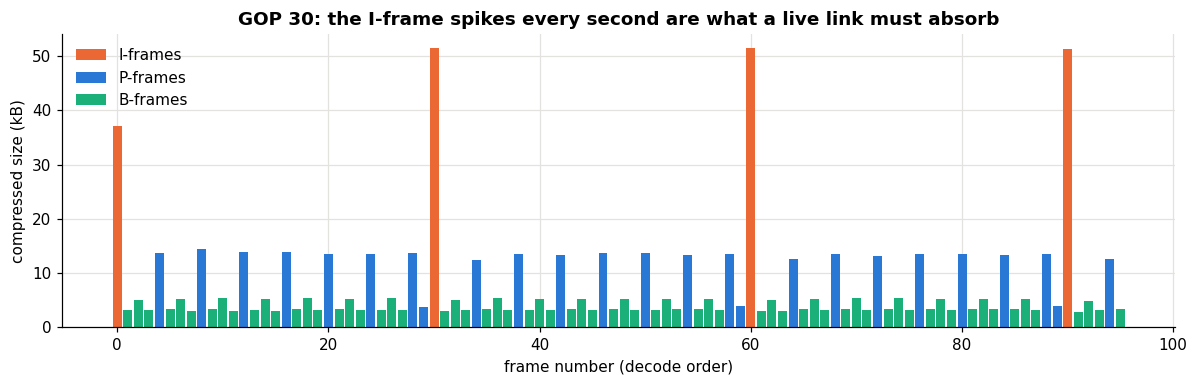

In [9]:
ft = ftypes["GOP 30"].iloc[:96]
colors = {"I": PALETTE[1], "P": PALETTE[0], "B": PALETTE[2]}
fig, ax = plt.subplots(figsize=(11, 3.6))
for t in ("I", "P", "B"):
    sel = ft[ft.type == t]
    ax.bar(sel.index, sel["size"] / 1e3, color=colors[t], width=0.85, label=f"{t}-frames")
ax.set_xlabel("frame number (decode order)"); ax.set_ylabel("compressed size (kB)")
ax.set_title("GOP 30: the I-frame spikes every second are what a live link must absorb"); ax.legend()
plt.tight_layout(); plt.show()

**Try it.** Change the keyframe interval and the number of B-frames. The bars are each frame's size, coloured by type.

In [10]:
TYPE_COLOUR = {"I": MIA_RED, "P": PALETTE[0], "B": PALETTE[2]}


def types_view(gop_s, bframes, scenecut):
    g = max(1, round(gop_s * FPS))
    args = ["-c:v", "libx264", "-preset", "veryfast", "-crf", "23", "-g", str(g), "-keyint_min", str(g), "-bf", str(bframes),
            *([] if scenecut else ["-sc_threshold", "0"])]
    res = encode_cached(args, "types"); ft = frame_types(res["file"])
    kb = lambda t: ft[ft.type == t]["size"].mean() / 1e3 if (ft.type == t).any() else float("nan")
    cards([("I-frames", f"{int((ft.type == 'I').sum())}", f"one every {g / FPS:.2f} s"),
           ("average I", f"{kb('I'):.0f} kB", f"{kb('I') / kb('P'):.1f}× a P-frame"),
           ("average P", f"{kb('P'):.1f} kB", "predicted from the past"),
           ("average B", "none" if bframes == 0 else f"{kb('B'):.1f} kB", "waits for a future frame" if bframes else "no waiting"),
           ("bitrate", rate(res["bitrate"]), f"SSIM {res['ssim']:.3f}")])
    show = ft.iloc[:120]
    plt.figure(figsize=(12, 3.2))
    plt.bar(show.index, show["size"] / 1e3, color=[TYPE_COLOUR.get(t, GREY) for t in show.type], width=0.85)
    plt.xlabel("frame (decode order)"); plt.ylabel("kB"); plt.title("red = I · blue = P · green = B"); plt.tight_layout(); plt.show()


panel("types", "Frame types", "Keyframe interval and B-frames",
      {"gop_s": ("options", [0.25, 0.5, 1.0, 2.0, 4.0], 1.0, "keyframe every (s)"),
       "bframes": ("int", (0, 3, 1), 0, "B-frames"),
       "scenecut": ("check", None, False, "extra I-frame on a scene cut")}, types_view)

**Look for**
- An I-frame is several times a P-frame (about 4× on the slide). Those spikes are what the tether must absorb every GOP.
- B-frames make the file smaller, but each one makes the encoder wait for a future frame. Live streams use 0.
- With scene-cut detection on, x264 adds an I-frame at the camera cut (frame ~120).

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 29 · EXPERIMENTS 3 AND 6 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Quality target or bitrate cap?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">CRF for recording, a capped bitrate for the live tether.</div>
</div>

In [11]:
CRFS = [18, 23, 28, 33, 38, 43]
TARGETS_MBPS = [0.25, 0.5, 1, 2, 4, 8]
rows = []
for crf in CRFS:
    out = WORK / f"e3_crf{crf}.mp4"
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-crf", str(crf), "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "CRF", "setting": f"crf {crf}", "bitrate_Mb/s": p["bitrate_mbps"], "size_MB": p["size_bytes"]/1e6,
                 "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
for tgt in TARGETS_MBPS:
    out = WORK / f"e3_vbv{tgt}.mp4"; kb = int(tgt * 1000)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
             "-b:v", f"{kb}k", "-maxrate", f"{kb}k", "-bufsize", f"{kb // 2}k",   # 0.5 s of buffer
             "-pix_fmt", "yuv420p", "-an", str(out)])
    p = probe(out); psnr, ssim = quality(out, SRC)
    rows.append({"mode": "Target bitrate (VBV)", "setting": f"{tgt} Mb/s", "bitrate_Mb/s": p["bitrate_mbps"],
                 "size_MB": p["size_bytes"]/1e6, "encode_s": r["wall_s"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e3 = pd.DataFrame(rows)
display(e3.drop(columns="file").style.format({"bitrate_Mb/s": "{:.2f}", "size_MB": "{:.2f}", "encode_s": "{:.1f}",
                                              "PSNR_dB": "{:.1f}", "SSIM": "{:.4f}"}).hide(axis="index"))

mode,setting,bitrate_Mb/s,size_MB,encode_s,PSNR_dB,SSIM
CRF,crf 18,2.48,1.86,7.0,48.1,0.9866
CRF,crf 23,1.50,1.13,3.7,46.4,0.9817
CRF,crf 28,0.93,0.70,3.5,44.0,0.9729
CRF,crf 33,0.51,0.38,2.9,40.9,0.9596
CRF,crf 38,0.16,0.12,2.4,38.2,0.9424
CRF,crf 43,0.08,0.06,1.9,36.6,0.9302
Target bitrate (VBV),0.25 Mb/s,0.15,0.12,2.4,37.8,0.9390
Target bitrate (VBV),0.5 Mb/s,0.37,0.27,3.0,39.7,0.9529
Target bitrate (VBV),1 Mb/s,0.73,0.54,3.2,42.5,0.9672
Target bitrate (VBV),2 Mb/s,1.40,1.05,4.3,45.9,0.9800


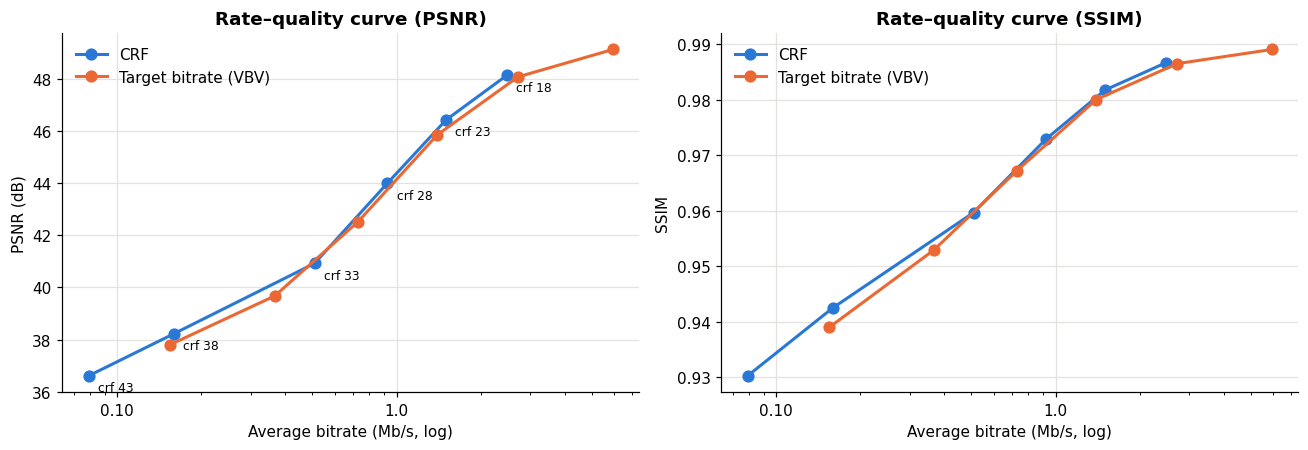

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (mode, g) in enumerate(e3.groupby("mode", sort=False)):
    axs[0].plot(g["bitrate_Mb/s"], g["PSNR_dB"], "o-", label=mode, color=PALETTE[k])
    axs[1].plot(g["bitrate_Mb/s"], g["SSIM"], "o-", label=mode, color=PALETTE[k])
for _, r in e3[e3["mode"] == "CRF"].iterrows():
    axs[0].annotate(r["setting"], (r["bitrate_Mb/s"], r["PSNR_dB"]), textcoords="offset points", xytext=(6, -10), fontsize=8)
for ax, yl in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt))
    ax.set_xlabel("Average bitrate (Mb/s, log)"); ax.set_ylabel(yl); ax.legend()
axs[0].set_title("Rate–quality curve (PSNR)"); axs[1].set_title("Rate–quality curve (SSIM)")
plt.tight_layout(); plt.show()

Now the part that matters on a tether: what the bitrate does **over time**. Both encodes below have the same average.

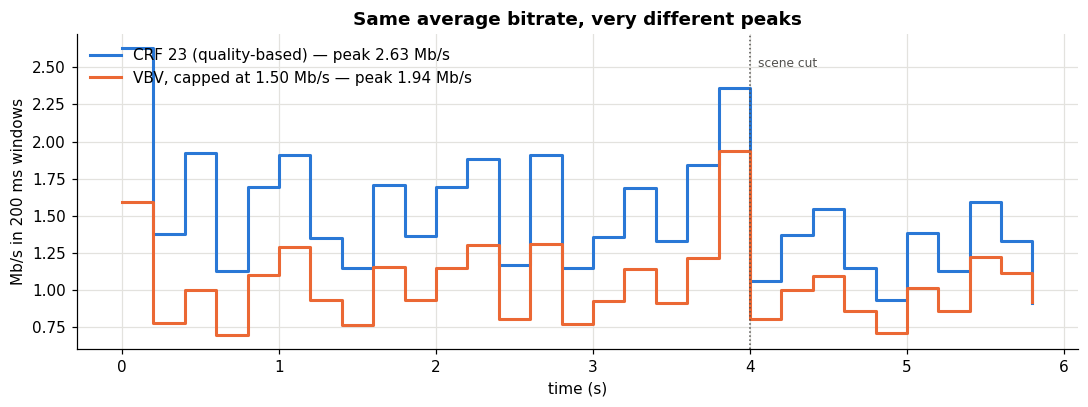

In [13]:
crf23 = e3[(e3["mode"] == "CRF") & (e3["setting"] == "crf 23")].iloc[0]
avg_kb = int(crf23["bitrate_Mb/s"] * 1000)
vbv_match = WORK / "e3_vbv_match.mp4"
run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "medium",
     "-b:v", f"{avg_kb}k", "-maxrate", f"{avg_kb}k", "-bufsize", f"{avg_kb // 3}k", "-pix_fmt", "yuv420p", "-an", str(vbv_match)])

def windowed_mbps(path, win=0.2):
    pk = packets(path); bins = np.floor(pk["pts"] / win)
    s = pk.groupby(bins)["size"].sum() * 8 / win / 1e6
    return s.index.values * win, s.values, pk

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (label, path) in enumerate((("CRF 23 (quality-based)", crf23["file"]), (f"VBV, capped at {avg_kb/1000:.2f} Mb/s", vbv_match))):
    t, mb, pk = windowed_mbps(path)
    ax.step(t, mb, where="post", label=f"{label} — peak {mb.max():.2f} Mb/s", color=PALETTE[k])
ax.axvline(4.0, color="#52514e", ls=":", lw=1); ax.text(4.05, ax.get_ylim()[1]*0.92, "scene cut", fontsize=8, color="#52514e")
ax.set_xlabel("time (s)"); ax.set_ylabel("Mb/s in 200 ms windows"); ax.set_title("Same average bitrate, very different peaks")
ax.legend(); plt.tight_layout(); plt.show()

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 32 · CHOOSING A CODEC · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">The fair comparison: whole rate–quality curves</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Which codec is best depends on where you sit on the curve.</div>
</div>

This cell encodes the clip at five quality levels per codec. It's the slowest cell in the notebook (a few minutes on a laptop); the results are cached. We use `-tune ssim` (metric-neutral tuning) so the encoders aren't optimising for how things look to people while we score them with SSIM.

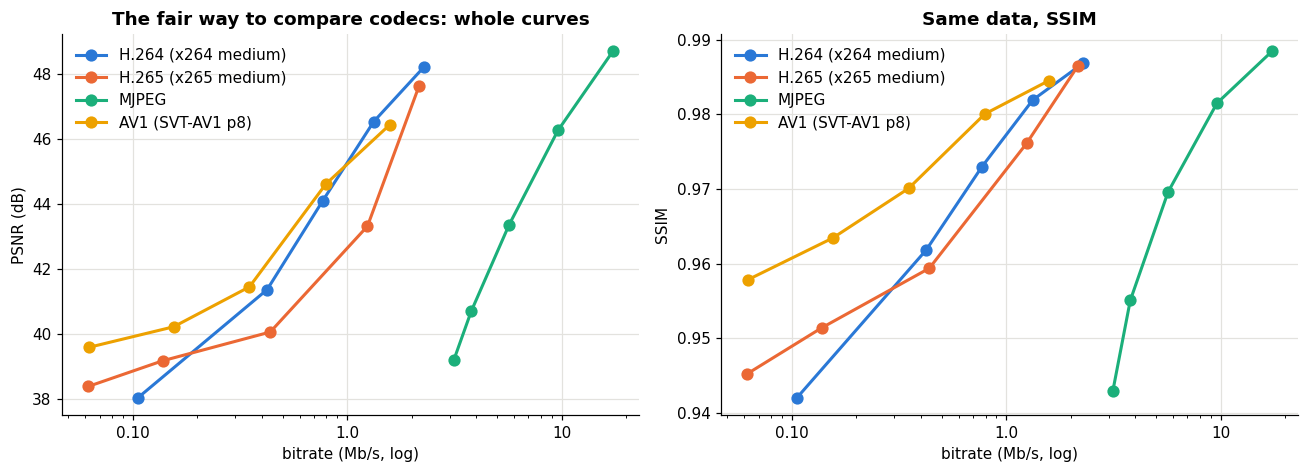

In [15]:
CURVES = {
    # Metric-neutral tuning: -tune ssim (x264/x265) and tune=1 (PSNR) for SVT-AV1 — see the note below.
    "H.264 (x264 medium)":  ("libx264",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx264", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p"], "mp4"),
    "H.265 (x265 medium)":  ("libx265",   [18, 23, 28, 33, 38], lambda q: ["-c:v", "libx265", "-preset", "medium", "-tune", "ssim", "-crf", str(q), "-pix_fmt", "yuv420p", "-x265-params", "log-level=error"], "mp4"),
    "MJPEG":                ("mjpeg",     [2, 4, 8, 16, 31],    lambda q: ["-c:v", "mjpeg", "-q:v", str(q), "-pix_fmt", "yuvj420p"], "mkv"),
    "AV1 (SVT-AV1 p8)":     ("libsvtav1", [24, 32, 40, 48, 56], lambda q: ["-c:v", "libsvtav1", "-preset", "8", "-crf", str(q), "-svtav1-params", "tune=1", "-pix_fmt", "yuv420p"], "mkv"),
}
rows = []
for codec, (enc, qs, mk, ext) in CURVES.items():
    if not HAS.get(enc): print("skip", codec); continue
    for q in qs:
        out = WORK / f"e6_{enc}_{q}.{ext}"
        if not out.exists():
            run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *mk(q), "-an", str(out)])
        p = probe(out); psnr, ssim = quality(out, SRC)
        rows.append({"codec": codec, "q": q, "bitrate_Mb/s": p["bitrate_mbps"], "PSNR_dB": psnr, "SSIM": ssim, "file": out})
e6 = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (codec, g) in enumerate(e6.groupby("codec", sort=False)):
    for ax, m in zip(axs, ("PSNR_dB", "SSIM")):
        ax.plot(g["bitrate_Mb/s"], g[m], "o-", color=PALETTE[k], label=codec)
for ax, m in zip(axs, ("PSNR (dB)", "SSIM")):
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(FuncFormatter(mbps_fmt)); ax.set_xlabel("bitrate (Mb/s, log)"); ax.set_ylabel(m); ax.legend()
axs[0].set_title("The fair way to compare codecs: whole curves"); axs[1].set_title("Same data, SSIM")
plt.tight_layout(); plt.show()

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 39 · EXPERIMENT 5 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Packet loss and the keyframe interval</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Damage lasts until the next I-frame; intra refresh heals without the spike.</div>
</div>

We delete a few kB from an MPEG-TS stream (as a lost burst of UDP packets would), decode it, and measure how long the picture stays broken. First at three loss positions for three settings, then in a panel where you choose.

variant,loss at 1.4s,loss at 2.5s,loss at 3.3s,mean damaged (s),worst (s)
GOP 30 (I-frame every 1 s),0.57,0.47,0.67,0.57,0.67
GOP 150 (I-frame every 5 s),3.57,1.40,1.67,2.21,3.57
Intra refresh over 30 frames,0.47,0.67,0.67,0.60,0.67


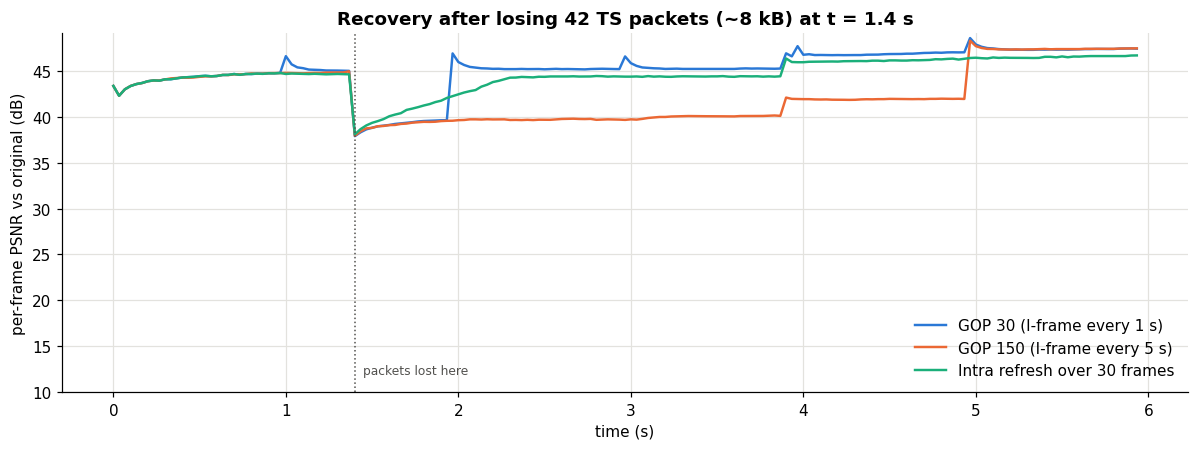

In [18]:
LOSS_T = 1.4                       # the loss we plot and look at
LOSS_TIMES = [1.4, 2.5, 3.3]       # repeat at three positions — one loss point is an anecdote, not a measurement
DROP_TS_PACKETS = 42               # 6 UDP datagrams × 7 TS packets
VARIANTS = {
    "GOP 30 (I-frame every 1 s)":   ["-g", "30", "-keyint_min", "30", "-sc_threshold", "0"],
    "GOP 150 (I-frame every 5 s)":  ["-g", "150", "-keyint_min", "150", "-sc_threshold", "0"],
    "Intra refresh over 30 frames": ["-g", "30", "-sc_threshold", "0", "-x264-params", "intra-refresh=1"],
}

def damage_seconds(clean, damaged):
    """Duration between the first and last frame that is > 3 dB worse than the undamaged encode."""
    n = min(len(clean), len(damaged)); bad = np.where(clean[:n] - damaged[:n] > 3)[0]
    return (bad.max() - bad.min() + 1) / FPS if len(bad) else 0.0

loss, rows = {}, []
for label, extra in VARIANTS.items():
    tag = re.sub(r"\W+", "_", label)[:20]
    ts = WORK / f"e5_{tag}.ts"
    # -threads 1: multi-threaded x264 with a capped bitrate is not bit-exact between runs; one thread makes this reproducible
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-c:v", "libx264", "-preset", "veryfast",
         "-tune", "zerolatency", "-threads", "1", "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra,
         "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); start_pts = pk["pts"].min(); data = ts.read_bytes()
    _, _, pf_clean = quality(ts, SRC, per_frame=True)
    durations = []
    for k, t_loss in enumerate(LOSS_TIMES):
        pos = int(pk.loc[(pk["pts"] - start_pts - t_loss).abs().idxmin(), "pos"]); pos -= pos % 188   # TS packet boundary
        damaged = WORK / f"e5_{tag}_damaged{k}.ts"
        damaged.write_bytes(data[:pos] + data[pos + 188 * DROP_TS_PACKETS:])
        dec = WORK / (f"e5_{tag}_decoded.mkv" if k == 0 else f"e5_{tag}_decoded{k}.mkv")
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(damaged), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
        _, _, pf_dam = quality(dec, SRC, per_frame=True)
        durations.append(damage_seconds(pf_clean, pf_dam))
        if k == 0: loss[label] = {"clean": pf_clean, "damaged": pf_dam, "ts": ts}
    rows.append({"variant": label, **{f"loss at {t}s": d for t, d in zip(LOSS_TIMES, durations)},
                 "mean damaged (s)": np.mean(durations), "worst (s)": np.max(durations)})
e5_loss = pd.DataFrame(rows)
display(e5_loss.style.format({c: "{:.2f}" for c in e5_loss.columns if c != "variant"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.2))
for k, (label, d) in enumerate(loss.items()):
    ax.plot(np.arange(len(d["damaged"])) / FPS, d["damaged"], label=label, color=PALETTE[k], lw=1.6)
ax.axvline(LOSS_T, color="#52514e", ls=":", lw=1); ax.text(LOSS_T + 0.05, 12, "packets lost here", fontsize=8, color="#52514e")
ax.set_ylim(10, None); ax.set_xlabel("time (s)"); ax.set_ylabel("per-frame PSNR vs original (dB)")
ax.set_title(f"Recovery after losing {DROP_TS_PACKETS} TS packets (~{DROP_TS_PACKETS*188/1000:.0f} kB) at t = {LOSS_T} s"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

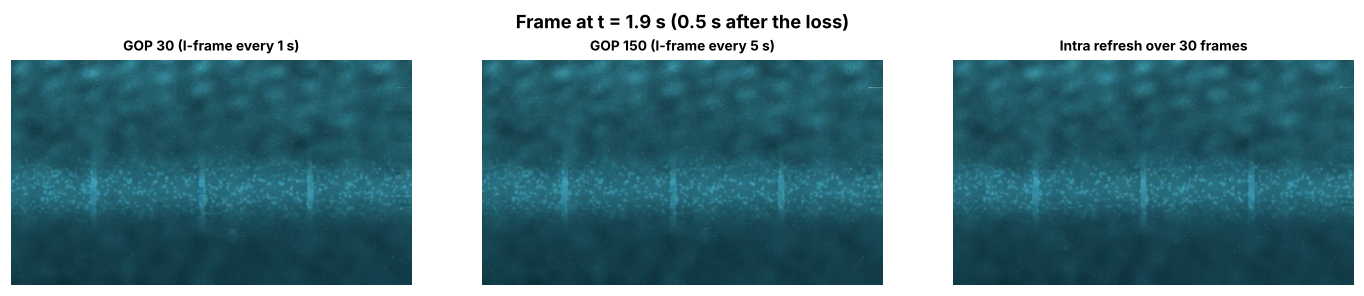

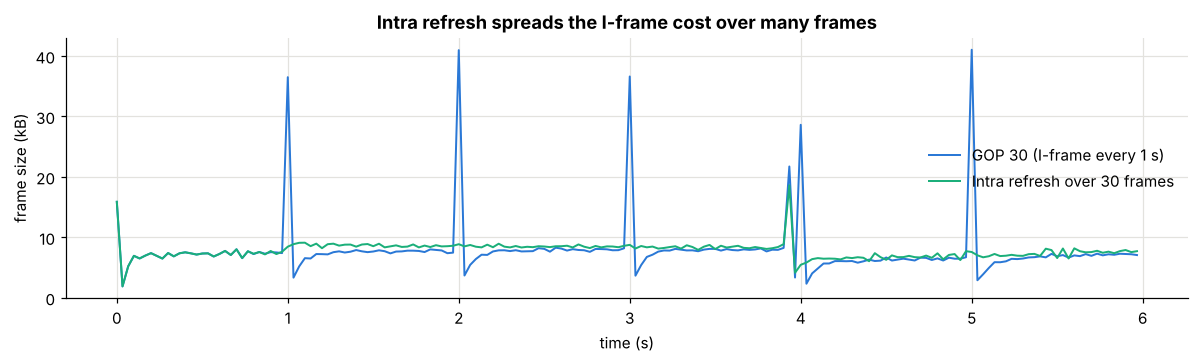

In [32]:
# What the pilot sees 0.5 s after the loss, and the bitrate smoothness of intra refresh
fig, axs = plt.subplots(1, 3, figsize=(13, 2.7))
for ax, (label, d) in zip(axs, loss.items()):
    tag = re.sub(r"\W+", "_", label)[:20]; png = WORK / f"e5_{tag}_after.png"
    run([FFMPEG, "-y", "-loglevel", "error", "-ss", str(LOSS_T + 0.5), "-i", str(WORK / f"e5_{tag}_decoded.mkv"), "-frames:v", "1", str(png)])
    ax.imshow(plt.imread(png)); ax.set_title(label, fontsize=9); ax.axis("off")
plt.suptitle(f"Frame at t = {LOSS_T + 0.5:.1f} s (0.5 s after the loss)", fontweight="bold"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.4))
for k, label in enumerate(["GOP 30 (I-frame every 1 s)", "Intra refresh over 30 frames"]):
    pk = packets(loss[label]["ts"]); ax.plot(np.arange(len(pk)) / FPS, pk["size"] / 1e3, label=label, color=PALETTE[[0, 2][k]], lw=1.3)
ax.set_xlabel("time (s)"); ax.set_ylabel("frame size (kB)"); ax.set_title("Intra refresh spreads the I-frame cost over many frames")
ax.legend(); plt.tight_layout(); plt.show()

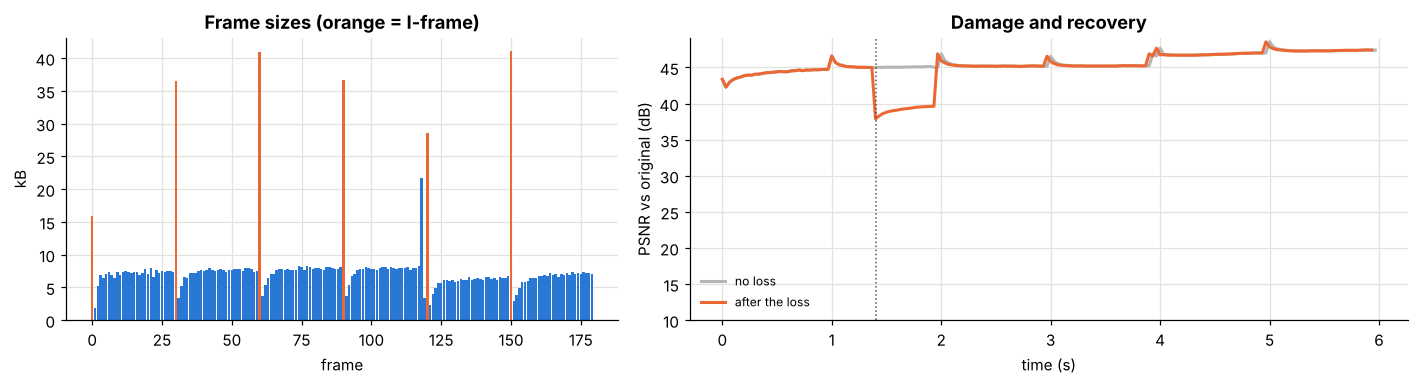

In [33]:
def tune_gop(gop_s, intra_refresh, loss_kb, loss_at):
    g = max(1, int(round(gop_s * FPS)))
    extra = (["-g", str(g), "-sc_threshold", "0", "-x264-params", "intra-refresh=1"] if intra_refresh
             else ["-g", str(g), "-keyint_min", str(g), "-sc_threshold", "0"])
    args = ["-c:v", "libx264", "-preset", "veryfast", "-tune", "zerolatency", "-threads", "1",
            "-b:v", "2000k", "-maxrate", "2000k", "-bufsize", "700k", *extra]
    key = hashlib.sha1(json.dumps(args).encode()).hexdigest()[:12]
    ts = WORK / f"tune_e5_{key}.ts"
    if not ts.exists():
        run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, *args, "-pix_fmt", "yuv420p", "-an", "-f", "mpegts", str(ts)])
    pk = packets(ts); data = ts.read_bytes()
    _, _, clean = quality(ts, SRC, per_frame=True)
    pos = int(pk.loc[(pk["pts"] - pk["pts"].min() - loss_at).abs().idxmin(), "pos"]); pos -= pos % 188
    n_drop = max(1, int(loss_kb * 1000 / 188))
    dam = WORK / "tune_e5_damaged.ts"; dam.write_bytes(data[:pos] + data[pos + 188 * n_drop:])
    dec = WORK / "tune_e5_decoded.mkv"
    run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", "-i", str(dam), "-c:v", "ffv1", "-pix_fmt", "yuv420p", str(dec)])
    _, _, broken = quality(dec, SRC, per_frame=True)
    mbps = len(data) * 8 / (N_FRAMES / FPS) / 1e6
    cards([("I-frames", f"{int(pk['key'].sum())}", "intra refresh: only the first" if intra_refresh else f"one every {g / FPS:.2f} s"),
           ("stream bitrate", f"{mbps:.2f} Mb/s", "incl. MPEG-TS overhead"),
           ("biggest frame", f"{pk['size'].max() / 1e3:.0f} kB", f"average {pk['size'].mean() / 1e3:.1f} kB"),
           ("broken picture", f"{damage_seconds(clean, broken):.2f} s", f"after losing {n_drop * 188 / 1000:.0f} kB",
            damage_seconds(clean, broken) <= 1.0),
           ("worst join wait", f"{g / FPS:.2f} s", "camera switch / new viewer")])
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
    axs[0].bar(np.arange(len(pk)), pk["size"] / 1e3, width=0.9, color=[PALETTE[1] if k else PALETTE[0] for k in pk["key"]])
    axs[0].set_xlabel("frame"); axs[0].set_ylabel("kB"); axs[0].set_title("Frame sizes (orange = I-frame)")
    tt = np.arange(len(broken)) / FPS
    axs[1].plot(np.arange(len(clean)) / FPS, clean, color="#b5b5b5", label="no loss")
    axs[1].plot(tt, broken, color=PALETTE[1], label="after the loss")
    axs[1].axvline(loss_at, color="#52514e", ls=":", lw=1); axs[1].set_ylim(10, None)
    axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("PSNR vs original (dB)"); axs[1].set_title("Damage and recovery"); axs[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

panel("e5", "Keyframes and packet loss", "Shorter GOP or intra refresh: how fast does the picture heal?",
             {"gop_s": ("options", [0.25, 0.5, 1.0, 2.0, 3.0, 5.0], 1.0, "keyframe every (s)"),
              "loss_kb": ("int", (1, 40, 1), 8, "data lost (kB)"),
              "loss_at": ("float", (0.5, 4.5, 0.1), 1.4, "loss at (s)"),
              "intra_refresh": ("check", None, False, "intra refresh instead of I-frames")}, tune_gop)

**Look for**
- GOP 150 can stay broken for seconds; GOP 30 and intra refresh recover in well under a second. Slide 39: 0.6 s vs 2.2 s on average, 3.6 s worst.
- Intra refresh has no I-frame spikes: the biggest frame is much smaller.
- "Camera switching takes two seconds" is often a two-second GOP: a new viewer waits for the next I-frame.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 40 · ACTIVITY 3 · PRESS ENCODE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">The blind test</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Rank five clips by quality, guess the bitrates, then reveal.</div>
</div>

**Try it.** Press **Encode**: you get five crops of the same frame at five hidden bitrates, labelled A to E in random order. Rank them and guess each bitrate. Then tick **reveal** and press Encode again (it's cached, so it's instant). Change the round number for a new set.

In [19]:
def blind_view(round_no, reveal):
    rng = np.random.default_rng(round_no)
    crfs = sorted(rng.choice(np.arange(18, 47, 2), 5, replace=False).tolist())
    clips = [(crf, encode_cached(["-c:v", "libx264", "-preset", "veryfast", "-crf", str(crf)], "blind")) for crf in crfs]
    order = rng.permutation(5)
    y0, x0 = int(0.48 * H), int(0.40 * W)
    fig, axs = plt.subplots(1, 5, figsize=(16, 3))
    for ax, letter, k in zip(axs, "ABCDE", order):
        ax.imshow(frame_png(clips[k][1]["file"], 2.0, f"blind_{letter}")[y0:y0 + 180, x0:x0 + 320]); ax.set_title(letter, fontsize=14, fontweight="bold"); ax.axis("off")
    plt.tight_layout(); plt.show()
    if reveal:
        rows = [{"clip": letter, "CRF": clips[k][0], "bitrate": rate(clips[k][1]["bitrate"]),
                 "PSNR (dB)": round(clips[k][1]["psnr"], 1), "SSIM": round(clips[k][1]["ssim"], 3)} for letter, k in zip("ABCDE", order)]
        display(pd.DataFrame(rows).sort_values("SSIM", ascending=False).style.hide(axis="index"))
    else:
        note("Rank A–E from best to worst and write a bitrate guess under each. Then tick reveal.")


panel("blind", "Blind test", "Five hidden bitrates, one frame",
      {"round_no": ("int", (1, 20, 1), 1, "round"), "reveal": ("check", None, False, "reveal the answers")}, blind_view)

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 04 · SLIDES 41–53</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Hardware, protocols and latency</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">Who does the work, how the bits travel, and where the milliseconds go.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 42 · WHO DOES THE WORK? · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Is the hardware encoder really there?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Listed is not working: always try a one-second encode.</div>
</div>

In [22]:
def board_model():
    for f in ("/proc/device-tree/model", "/sys/firmware/devicetree/base/model"):
        try: return Path(f).read_text(errors="ignore").strip("\x00\n ")
        except Exception: pass
    return platform.processor() or platform.machine()
IS_JETSON = Path("/etc/nv_tegra_release").exists()
MODEL = board_model(); IS_PI5 = "Raspberry Pi 5" in MODEL
print(f"Machine: {MODEL} | Jetson: {IS_JETSON} | Raspberry Pi 5: {IS_PI5} | cores: {CPU_CORES}")
if IS_JETSON: print(Path("/etc/nv_tegra_release").read_text().strip())

# Try each hardware encoder FFmpeg knows about with a 1-second test pattern. Being listed ≠ working!
TRY = {"h264_nvenc (NVIDIA desktop GPU)": ["-c:v", "h264_nvenc"],
       "h264_qsv (Intel Quick Sync)": ["-c:v", "h264_qsv"],
       "h264_vaapi (Intel/AMD via VA-API)": ["-vaapi_device", "/dev/dri/renderD128", "-vf", "format=nv12,hwupload", "-c:v", "h264_vaapi"],
       "h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)": ["-c:v", "h264_v4l2m2m"]}
rows = []
for name, args in TRY.items():
    pre = args[:2] if args[0] == "-vaapi_device" else []; post = args[2:] if pre else args
    r = run([FFMPEG, "-hide_banner", "-loglevel", "error", *pre, "-f", "lavfi", "-i", "testsrc2=size=1280x720:rate=30",
             "-t", "1", *post, "-f", "null", "-"], check=False)
    rows.append({"encoder": name, "listed in ffmpeg -encoders": HAS.get(name.split()[0], False),
                 "works on this machine": r["rc"] == 0, "error (first line)": "" if r["rc"] == 0 else (r["stderr"].strip().splitlines() or ["?"])[0][:90]})
display(pd.DataFrame(rows).style.hide(axis="index"))
print("→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.")

Machine: x86_64 | Jetson: False | Raspberry Pi 5: False | cores: 8


encoder,listed in ffmpeg -encoders,works on this machine,error (first line)
h264_nvenc (NVIDIA desktop GPU),True,False,[h264_nvenc @ 0x5e6b44e06100] Cannot load libcuda.so.1
h264_qsv (Intel Quick Sync),True,False,[h264_qsv @ 0x5d572cdb7100] Error creating a MFX session: -9.
h264_vaapi (Intel/AMD via VA-API),True,False,[AVHWDeviceContext @ 0x5a04a0704200] Failed to initialise VAAPI connection: -1 (unknown li
"h264_v4l2m2m (V4L2 mem2mem, e.g. Raspberry Pi 4)",True,False,[h264_v4l2m2m @ 0x5ca6d842e100] Could not find a valid device


→ An encoder appearing in `ffmpeg -encoders` only means FFmpeg was COMPILED with it. Always run a test encode.


**Look for**
- An encoder in `ffmpeg -encoders` only means FFmpeg was built with it. On a laptop without the GPU, every hardware encoder above fails.
- On a Jetson Nano the encoder is used through GStreamer (`nvv4l2h264enc`), not upstream FFmpeg. On a Raspberry Pi 5 there is no H.264 hardware encoder at all.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 43–45 · JETSON NANO VS RASPBERRY PI 5 · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">How many streams can the ROV computer encode?</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Measure one core here, then compare with the boards.</div>
</div>

First we measure how many frames per second **one core of this computer** encodes with x264 (PyAV if installed, otherwise FFmpeg with one thread).

In [38]:
from fractions import Fraction
try:
    import av
    HAVE_AV = True
except ImportError:
    HAVE_AV = False
    print("PyAV is not installed (pip install av): using FFmpeg with one thread instead.")

src_frames = []
if HAVE_AV:
    with av.open(str(SRC)) as cont:
        for i, fr in enumerate(cont.decode(video=0)):
            src_frames.append(fr.reformat(format="yuv420p"))
            if i >= 89:
                break

In [39]:
def one_core_fps(w, h, preset="ultrafast", n=60):
    """Frames per second that ONE thread of x264 sustains at w×h (encode time only)."""
    if HAVE_AV:
        frames = [f.reformat(width=w, height=h, format="yuv420p") for f in src_frames[:n]]
        ctx = av.CodecContext.create("libx264", "w"); ctx.width, ctx.height, ctx.pix_fmt = w, h, "yuv420p"
        ctx.time_base = Fraction(1, FPS); ctx.framerate = Fraction(FPS, 1); ctx.thread_count = 1
        ctx.options = {"preset": preset, "tune": "zerolatency", "b": "2500k"}
        t0 = time.perf_counter()
        for i, fr in enumerate(frames):
            fr.pts = i; ctx.encode(fr)
        ctx.encode(None); return n / (time.perf_counter() - t0)
    r = run([FFMPEG, "-y", "-hide_banner", "-loglevel", "error", *SRC_IN, "-vf", f"scale={w}:{h}", "-c:v", "libx264",
             "-preset", preset, "-tune", "zerolatency", "-threads", "1", "-b:v", "2500k", "-f", "null", "-"])
    return N_FRAMES / r["wall_s"]          # fallback: includes scaling cost
cap = []
for (w, h) in ((640, 360), (1280, 720), (1920, 1080)):
    for pr in ("ultrafast", "veryfast"):
        fps1 = one_core_fps(w, h, pr)
        cap.append({"resolution": f"{w}×{h}", "preset": pr, "fps on ONE core": fps1, "30-FPS streams per core (upper bound)": fps1 / 30,
                    f"streams on {max(CPU_CORES-1,1)} spare cores": fps1 / 30 * max(CPU_CORES - 1, 1)})
display(pd.DataFrame(cap).style.format({"fps on ONE core": "{:.0f}", "30-FPS streams per core (upper bound)": "{:.1f}",
                                         f"streams on {max(CPU_CORES-1,1)} spare cores": "{:.1f}"}).hide(axis="index"))

resolution,preset,fps on ONE core,30-FPS streams per core (upper bound),streams on 1 spare cores
640×360,ultrafast,912,30.4,30.4
640×360,veryfast,236,7.9,7.9
1280×720,ultrafast,403,13.4,13.4
1280×720,veryfast,81,2.7,2.7
1920×1080,ultrafast,206,6.9,6.9
1920×1080,veryfast,43,1.4,1.4


**Try it.** Now plan the ROV computer. The Jetson Nano's encoder is rated 4 × 1080p30 (NVIDIA). The Pi 5 has no encoder; Raspberry Pi's April 2026 white paper measured 0.62–0.9 of one Cortex-A76 core per 1080p30 low-latency stream. These are vendor numbers, not ours: soak-test before you buy (slide 45).

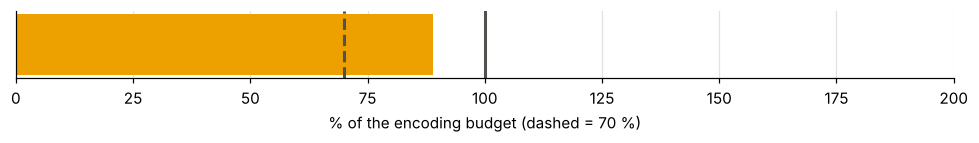

In [40]:
BOARD_RES = {"640×360": (640, 360), "1280×720": (1280, 720), "1920×1080": (1920, 1080)}
P1080 = 1920 * 1080 * 30


def board_view(board, streams, res, fps, pi_core_cost, free_cores):
    w, h = BOARD_RES[res]; px = streams * w * h * fps
    if board == "Jetson Nano":
        load = px / (4 * P1080); fit = int(4 * P1080 // (w * h * fps)); detail = "share of the hardware encoder"
    elif board == "Raspberry Pi 5":
        need = px / P1080 * pi_core_cost; load = need / free_cores
        fit = int(free_cores / (w * h * fps / P1080 * pi_core_cost)); detail = f"{need:.1f} of {free_cores} free cores"
    else:
        load, fit, detail = 0.0, 99, "the computer only forwards packets"
    cards([("load", f"{load:.0%}", detail, load <= 0.7),
           ("streams that fit", "any" if fit >= 99 else f"{fit}", f"{res} @ {fps} fps"),
           ("verdict", "OK" if load <= 0.7 else ("tight" if load <= 1 else "over"), "plan for 70 % or less", load <= 0.7)])
    plt.figure(figsize=(9, 1.4)); plt.barh([0], [min(load, 2) * 100], color=GOOD if load <= 0.7 else (PALETTE[3] if load <= 1 else BAD), height=0.5)
    plt.axvline(70, ls="--", color="#52514e"); plt.axvline(100, color="#52514e"); plt.xlim(0, 200); plt.yticks([])
    plt.xlabel("% of the encoding budget (dashed = 70 %)"); plt.tight_layout(); plt.show()


panel("board", "Encoder budget", "Who encodes decides which board wins",
      {"board": ("toggle", ["Jetson Nano", "Raspberry Pi 5", "Cameras encode themselves"], "Jetson Nano", "who encodes"),
       "streams": ("int", (1, 8, 1), 8, "streams"), "res": ("options", list(BOARD_RES), "1280×720", "resolution"),
       "fps": ("options", [10, 15, 30], 30, "fps"), "pi_core_cost": ("options", [0.62, 0.76, 0.9], 0.76, "Pi 5 cores per 1080p30"),
       "free_cores": ("options", [1.0, 2.0, 2.5, 3.0, 3.5], 2.5, "Pi 5 cores free for video")}, board_view, live=True)

**Look for**
- Eight 720p30 streams fit the Nano's encoder (9 × 720p30 is its limit). On a Pi 5 the same job needs far more cores than it has.
- If the cameras encode themselves, the board only forwards packets, and the Pi 5's faster CPU becomes the better choice.
- Also watch out for the Jetson **Orin** Nano: no hardware video encoder at all.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 48 · EXPERIMENT 9 ESTIMATE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Build your own latency budget</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">FPS is not latency: a perfect 30 fps stream can be two seconds late.</div>
</div>

**Try it.** Pick each stage the way our system is set up today, then fix the biggest bar first. These are **estimates** built from typical values and our one measured number (x264 defaults hold 41 frames). Measure the real total with the ms-clock photo (slide 57, experiment E1).

In [24]:
ENCODER_HOLD = {"x264 zerolatency (0 frames)": 0, "MJPEG (0 frames)": 0, "x264 defaults (41 frames)": 41}
PLAYER = {"low-delay player (0 ms)": 0, "VLC default cache (1,000 ms)": 1000, "HLS in a browser (≈ 6,000 ms)": 6000}
SCREEN = {"monitor 60 Hz (≈ 17 ms)": 17, "TV in game mode (≈ 25 ms)": 25, "TV, normal mode (≈ 100 ms)": 100}


def budget_view(fps, encoder, encode_ms, network_ms, jitter_ms, player, decode_ms, screen):
    stages = {"capture": 1000 / fps, "encode": ENCODER_HOLD[encoder] * 1000 / fps + encode_ms, "network": network_ms,
              "jitter buffer": jitter_ms, "player cache": PLAYER[player], "decode": decode_ms, "display": SCREEN[screen]}
    total = sum(stages.values()); worst = max(stages, key=stages.get)
    cards([("glass-to-glass", f"{total:,.0f} ms", "target ≤ 150 ms", total <= 150),
           ("biggest stage", worst, f"{stages[worst]:,.0f} ms: fix this first"),
           ("network share", f"{network_ms / total:.0%}", "the cable is rarely the problem")])
    fig, ax = plt.subplots(figsize=(12, 3.2)); left = 0
    for k, (name, v) in enumerate(stages.items()):
        ax.barh(0, v, left=left, color=[MIA_RED, *PALETTE][k % 9], edgecolor="white", height=0.5, label=f"{name}: {v:,.0f} ms")
        left += v
    ax.axvline(150, color="#111", ls="--", lw=1); ax.text(150, 0.32, " target 150 ms", fontsize=8)
    ax.set_ylim(-0.4, 0.45); ax.set_xlim(0, max(left, 160) * 1.03); ax.set_yticks([])
    ax.set_xlabel("glass-to-glass, ms (ESTIMATE)"); ax.set_title(f"≈ {left:,.0f} ms from the camera to the pilot's eye")
    fig.legend(ncol=4, fontsize=8.5, loc="lower center", frameon=False); fig.subplots_adjust(left=0.03, right=0.98, top=0.85, bottom=0.42)
    plt.show()


panel("budget", "Latency budget", "Where the milliseconds go",
      {"encoder": ("toggle", list(ENCODER_HOLD), "x264 defaults (41 frames)", "encoder"),
       "player": ("toggle", list(PLAYER), "VLC default cache (1,000 ms)", "player"),
       "screen": ("toggle", list(SCREEN), "TV in game mode (≈ 25 ms)", "screen"),
       "fps": ("options", [15, 25, 30, 60], 30, "camera fps"), "encode_ms": ("int", (1, 40, 1), 9, "encode time (ms)"),
       "network_ms": ("options", [1, 3, 10, 30], 3, "network (ms)"), "jitter_ms": ("options", [0, 15, 30, 50, 100, 200], 50, "jitter buffer (ms)"),
       "decode_ms": ("int", (1, 30, 1), 8, "decode (ms)")}, budget_view, live=True)

**Look for**
- The default setup on the slide is about 2.4 s; zerolatency + a low-delay player + game mode gets it near 130 ms. The cable is a few ms either way.
- Check the pipeline in this order: player buffer, encoder hold, screen, then everything else.

**Look for**
- 1 main + 7 substreams needs roughly a quarter of "everything at full quality" (slide 50: 5.4 vs 19.8 Mb/s).
- A substream only has to answer "is something happening there?" When the pilot makes a camera big, switch it to the main stream.

<div style="border-radius:18px; padding:22px 26px; margin:40px 0 6px; background:#1d1d1f; color:#ffffff">
<div style="font-size:11px; letter-spacing:.3em; color:#ff8a8a">PART 05 · SLIDES 54–61</div>
<div style="font-size:26px; font-weight:800; margin-top:6px">Diagnostics</div>
<div style="font-size:14px; color:#c8c8c8; margin-top:4px">One cause, one stage. Measure before you change anything.</div>
</div>

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 54 · 72 · WHERE IS THE PROBLEM? · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">Latency drift: a queue that only grows</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">30 fps in, 29.7 fps out: 10 ms more delay every second.</div>
</div>

**Try it.** Frames arrive at the camera's rate and leave at the display's rate. If they arrive even slightly faster, a queue grows and nobody notices until the pilot is seconds behind. Then put a limit on the queue.

In [28]:
def drift_view(camera_fps, display_fps, queue_limit, minutes):
    t = np.linspace(0, minutes * 60, 600)
    surplus = max(camera_fps - display_fps, 0)                   # frames per second that pile up
    waiting = surplus * t
    if queue_limit != "no limit":
        waiting = np.minimum(waiting, queue_limit)
    latency = 33 + waiting * 1000 / display_fps
    dropped = surplus * minutes * 60 - waiting[-1]
    cards([("delay after", f"{latency[-1] / 1000:.2f} s", f"{minutes} min into the dive", latency[-1] < 150),
           ("growth", f"{surplus * 1000 / display_fps:.0f} ms / s" if queue_limit == "no limit" else "capped",
            "while the queue is unlimited"),
           ("frames dropped", f"{dropped:,.0f}", "the cure: drop old frames, keep new ones")])
    plt.figure(figsize=(10, 3)); plt.plot(t / 60, latency, color=MIA_RED)
    plt.xlabel("minutes"); plt.ylabel("delay (ms)"); plt.title("The picture the pilot sees falls behind"); plt.tight_layout(); plt.show()


panel("drift", "Latency drift", "A rate mismatch you can't see until it's seconds long",
      {"camera_fps": ("options", [25, 29.97, 30, 30.3], 30, "frames in (fps)"), "display_fps": ("options", [25, 29.7, 29.97, 30, 60], 29.7, "frames shown (fps)"),
       "queue_limit": ("options", ["no limit", 1, 2, 5], "no limit", "queue limit (frames)"), "minutes": ("int", (1, 30, 1), 10, "dive length (min)")}, drift_view, live=True)

**Look for**
- 0.3 frames per second of surplus is invisible on any fps counter, and it's still 6 seconds of delay after 10 minutes.
- A queue of 1–2 frames that drops the oldest frame keeps the delay flat. Every queue in the pipeline needs a limit.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 73 · FIELD GUIDE · LIVE: CHANGES AS YOU DRAG</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">A frozen picture that looks live</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">The fps counter keeps saying 30 while the frame on screen gets older.</div>
</div>

**Try it.** The stream stops for a moment (a crashed encoder, a camera dropping off USB). The renderer keeps redrawing the last frame, so the fps counter never moves. Only the **age of the frame** shows the freeze. Choose when the STALE badge should appear.

In [29]:
def stale_view(freeze_at, freeze_len, threshold_ms):
    t = np.arange(0, 10, 1 / 60)                                  # the screen refreshes at 60 Hz
    captures = np.arange(0, 10, 1 / 30)
    captures = captures[(captures < freeze_at) | (captures >= freeze_at + freeze_len)]
    last = captures[np.searchsorted(captures, t, side="right") - 1]
    age = (t - last) * 1000
    warned = age > threshold_ms
    blind = (age[(t >= freeze_at) & (t < freeze_at + freeze_len)] <= threshold_ms).sum() / 60
    cards([("fps counter", "30.0", "during the whole freeze", False),
           ("worst frame age", f"{age.max():,.0f} ms", "what the pilot actually saw"),
           ("STALE shown", "never" if not warned.any() else f"after {threshold_ms} ms", "", warned.any()),
           ("driving on an old picture, unwarned", f"{blind:.2f} s", "", blind < 0.6)])
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(t, age, color=PALETTE[0], label="age of the frame on screen")
    ax.axhline(threshold_ms, color=MIA_RED, ls="--", label=f"STALE after {threshold_ms} ms")
    ax.fill_between(t, 0, age.max() * 1.05, where=warned, color=MIA_RED, alpha=0.12, label="badge visible")
    ax.set_xlabel("time (s)"); ax.set_ylabel("ms"); ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()


panel("stale", "Stale frame", "Show the frame's age, not just the fps",
      {"freeze_at": ("float", (1, 7, 0.5), 3, "freeze starts (s)"), "freeze_len": ("options", [0.2, 0.5, 1, 2, 3], 2, "freeze lasts (s)"),
       "threshold_ms": ("options", [100, 250, 500, 1000, 3000], 500, "STALE after (ms)")}, stale_view, live=True)

**Look for**
- The field guide's rule: STALE after 500 ms without a new frame, LOST after a few seconds. Experiment E14 (`kill -STOP` on the encoder) checks whether our GUI does it.

<div style="border-radius:16px; padding:15px 22px; margin:30px 0 8px; color:#ffffff;
background:linear-gradient(115deg, #C00000 0%, #7d0000 100%); box-shadow:0 6px 18px rgba(192,0,0,.16)">
<div style="font-size:11px; letter-spacing:.22em; color:#ffd0d0">SLIDE 62 · ENGINEERING LOG · RUNS ONCE</div>
<div style="font-size:21px; font-weight:700; margin-top:4px">What this run measured</div>
<div style="font-size:13px; color:#ffe3e3; margin-top:3px">Paste these into your team's log.</div>
</div>

In [62]:
# Summary of key numbers measured in this run (paste into your team's engineering log)
summary = {
    "machine": MODEL, "ffmpeg": run([FFMPEG, "-hide_banner", "-version"])["stdout"].splitlines()[0],
    "raw 1080p30 RGB24 (Mb/s)": round(raw_mbps(1920, 1080, 30, 24)),
    "H.264 CRF23 clip bitrate (Mb/s)": round(float(e3[(e3['mode']=='CRF') & (e3['setting']=='crf 23')]['bitrate_Mb/s'].iloc[0]), 2),
    f"SSIM target used": SSIM_TARGET,
    "bits/pixel at target": {k: round(v, 4) for k, v in CODEC_BPP.items()},
    "x264 default encoder hold (frames)": enc_delay.get("x264 medium (defaults)", {}).get("frames held before first output"),
    "x264 zerolatency hold (frames)": enc_delay.get("x264 veryfast + tune zerolatency", {}).get("frames held before first output"),
}
(WORK / "summary.json").write_text(json.dumps(summary, indent=2, default=str)); print(json.dumps(summary, indent=2, default=str))

{
  "machine": "x86_64",
  "ffmpeg": "ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers",
  "raw 1080p30 RGB24 (Mb/s)": 1493,
  "H.264 CRF23 clip bitrate (Mb/s)": 1.9,
  "SSIM target used": 0.981,
  "bits/pixel at target": {
    "H.264": 0.0454,
    "H.265": 0.0583,
    "MJPEG": 0.34,
    "AV1": 0.077
  },
  "x264 default encoder hold (frames)": 41,
  "x264 zerolatency hold (frames)": 0
}
